# Simulated Annealing Schedules

Michael Hahsler

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Cooling Schedules

### Exponential Schedule

See [1].

In [2]:
def temperature_exponential(time, initial_temperature, alpha):
    return initial_temperature * alpha**time

### Linear Schedule

See [1].

In [3]:
def temperature_linear(time, initial_temperature, eta):
    return initial_temperature - eta * time

### Fast Simulated Annealing

See [3].

In [4]:
def temperature_fast(time, initial_temperature):
    return initial_temperature / (1 + time)

### Logarithmic (Classic) Cooling

If $T_0$ is greater than or equal to the largest energy barrier in the problem, this schedule is guaranteed to find the global optimum in the limit of infinite time [2]. The schedule is defined for $t > 0$.

In [5]:
def temperature_logarithmic(time, initial_temperature):
    return initial_temperature / np.log1p(time)

## Comparison

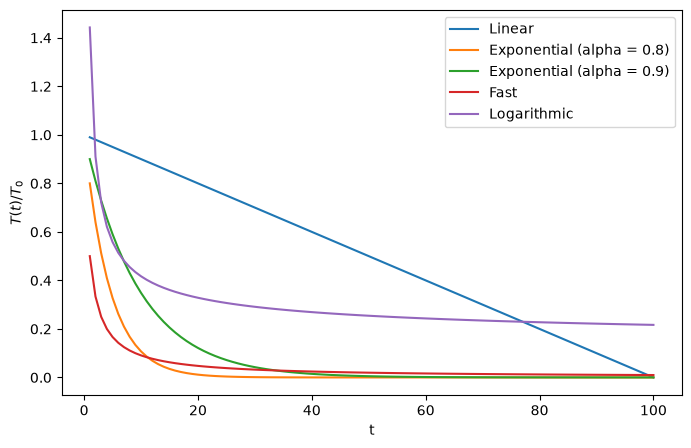

In [6]:
time = np.arange(1, 101)
initial_temperature = 1

schedules = {
    "Linear": temperature_linear(time, initial_temperature, eta=0.01),
    "Exponential (alpha = 0.8)": temperature_exponential(
        time, initial_temperature, alpha=0.8
    ),
    "Exponential (alpha = 0.9)": temperature_exponential(
        time, initial_temperature, alpha=0.9
    ),
    "Fast": temperature_fast(time, initial_temperature),
    "Logarithmic": temperature_logarithmic(time, initial_temperature),
}

plt.figure(figsize=(8, 5))
for name, temperature in schedules.items():
    plt.plot(time, temperature / initial_temperature, label=name)

plt.xlabel("t")
plt.ylabel(r"$T(t) / T_0$")
plt.legend()
plt.show()

## Literature

1. Kirkpatrick, S., Gelatt, C. D. Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
2. Hajek, B. (1988). Cooling schedules for optimal annealing. *Mathematics of Operations Research*, 13, 311–329.
3. Szu, H., and Hartley, R. (1987). Fast simulated annealing. *Physics Letters A*, 122(3–4), 157–162. [doi:10.1016/0375-9601(87)90796-1](https://doi.org/10.1016/0375-9601(87)90796-1)

## Bài 5: Khảo sát ảnh hưởng của alpha, eta và T0

Giữ nguyên các ô ở trên; các ô dưới đây thay đổi tham số và so sánh các lịch giảm nhiệt.
Lưu ý: lịch tuyến tính có thể về 0 hoặc âm khi `t >= T0/eta`, nên khi dùng trong SA phải chặn `T > 0`; lịch logarithmic chỉ xác định với `t > 0` và `T(1) = T0/ln 2 > T0`.

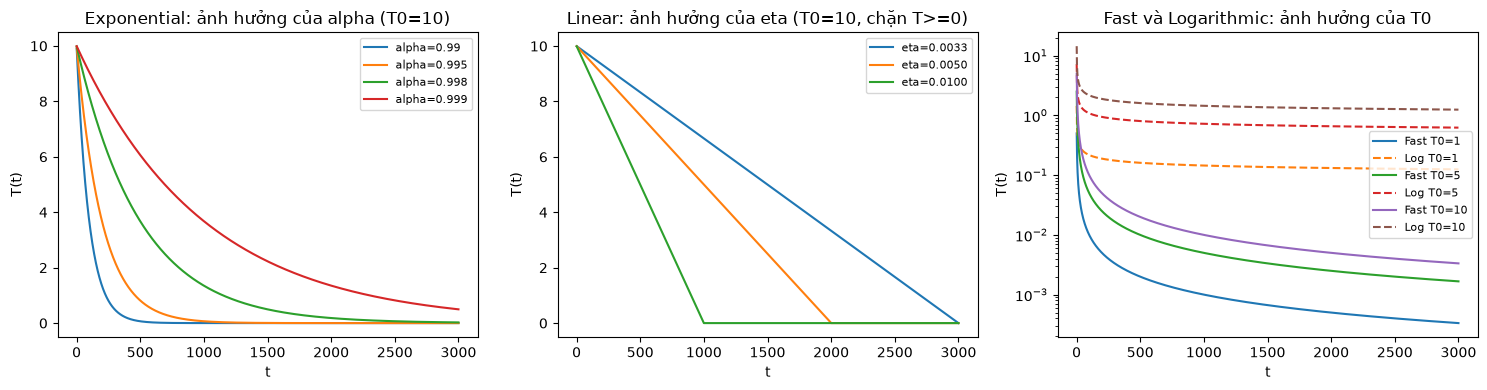

In [7]:
# (a) Thay đổi alpha, eta, T0 (T(t) tuyệt đối, T0 = 10, t = 1..3000)
t = np.arange(1, 3001)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for a in (0.99, 0.995, 0.998, 0.999):
    axes[0].plot(t, temperature_exponential(t, 10, a), label=f"alpha={a}")
axes[0].set_title("Exponential: ảnh hưởng của alpha (T0=10)")

for e in (10 / 3000, 10 / 2000, 10 / 1000):
    axes[1].plot(t, np.maximum(temperature_linear(t, 10, e), 0), label=f"eta={e:.4f}")
axes[1].set_title("Linear: ảnh hưởng của eta (T0=10, chặn T>=0)")

for T0_ in (1, 5, 10):
    axes[2].plot(t, temperature_fast(t, T0_), label=f"Fast T0={T0_}")
    axes[2].plot(t, temperature_logarithmic(t, T0_), "--", label=f"Log T0={T0_}")
axes[2].set_title("Fast và Logarithmic: ảnh hưởng của T0")
axes[2].set_yscale("log")

for ax in axes:
    ax.set_xlabel("t"); ax.set_ylabel("T(t)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [8]:
# (b) Lịch nào cho phép chấp nhận bước xấu lâu hơn?
# Với bước xấu Delta = 1, xác suất chấp nhận là p = exp(-1/T(t)).
# Đếm số bước t (trong 1..3000) mà p >= 5% (tức T >= 1/ln(20) ~ 0.334), cùng T0 = 10.
t = np.arange(1, 3001)
T0_ = 10.0
cands = {
    "Linear (eta=T0/3000)":   np.maximum(temperature_linear(t, T0_, T0_ / 3000), 1e-12),
    "Exponential (a=0.99)":   temperature_exponential(t, T0_, 0.99),
    "Exponential (a=0.995)":  temperature_exponential(t, T0_, 0.995),
    "Exponential (a=0.999)":  temperature_exponential(t, T0_, 0.999),
    "Fast":                   temperature_fast(t, T0_),
    "Logarithmic":            temperature_logarithmic(t, T0_),
}
print(f"{'Lịch nhiệt':<24}{'T(100)':>9}{'T(3000)':>10}{'p(Delta=1) tại t=3000':>24}{'#bước có p>=5%':>16}")
for name, T in cands.items():
    p = np.exp(-1 / T)
    print(f"{name:<24}{T[99]:>9.4f}{T[-1]:>10.4f}{p[-1]:>24.2e}{int((p >= 0.05).sum()):>16d}")

Lịch nhiệt                 T(100)   T(3000)   p(Delta=1) tại t=3000  #bước có p>=5%
Linear (eta=T0/3000)       9.6667    0.0000                0.00e+00            2899
Exponential (a=0.99)       3.6603    0.0000                0.00e+00             338
Exponential (a=0.995)      6.0577    0.0000                0.00e+00             678
Exponential (a=0.999)      9.0479    0.4971                1.34e-01            3000
Fast                       0.0990    0.0033               4.66e-131              28
Logarithmic                2.1668    1.2490                4.49e-01            3000


**Nhận xét:**

* Với T0 = 10 và bước xấu Delta = 1, xác suất chấp nhận exp(-1/T) còn >= 5% trong 3000 bước (Logarithmic và Exponential alpha = 0.999), 2899 bước (Linear), 678 (Exponential alpha = 0.995), 338 (alpha = 0.99) và chỉ 28 bước (Fast). Vậy Logarithmic, Linear và Exponential với alpha gần 1 chấp nhận bước xấu lâu nhất; Fast ngắn nhất.
* alpha càng gần 1, eta càng nhỏ hoặc T0 càng lớn thì nhiệt độ giảm càng chậm, SA khám phá lâu hơn. Ở hình 3 ô đầu: Exponential với alpha = 0.999 vẫn còn T ~ 0,5 ở t = 3000; Linear với eta = 0,01 về 0 tại t = 1000 và phần sau bị chặn bằng 0 (SA dừng ở đó).
* Logarithmic có T(1) = T0/ln 2 lớn hơn T0 và giảm rất chậm (T(3000) ~ 1,25 khi T0 = 10); Fast giảm cực nhanh lúc đầu rồi gần như đóng băng (T(100) ~ 0,1); Linear giữ nhiệt cao rồi rơi về 0 đúng tại t = T0/eta; Exponential giảm đều theo cấp số nhân.
* Lịch nguội chậm không phải lúc nào cũng cho nghiệm tốt hơn: kết quả SA trên 8 quân hậu với bốn lịch và hai giá trị T0 nằm trong `n_queens.ipynb`, ô "Bài 5".